In [4]:

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Download the required NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Original paragraph
text = """My favorite topic is artificial intelligence because it is transforming the way people live and work.
Machine learning allows computers to learn from data and make useful predictions.
I find it fascinating that intelligent systems can recognize images, understand language, and recommend music.
In healthcare, artificial intelligence can help doctors detect diseases earlier.
I also enjoy learning how chatbots communicate with humans and solve everyday problems.
I believe that responsible use of technology will create exciting opportunities for future generations."""

# 1. Convert text to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("1. Cleaned Text:")
print(clean_text)

# 2. Tokenize into sentences and words
sentences = sent_tokenize(text)
words = word_tokenize(clean_text)

print("\n2. Sentence Tokens:")
print(sentences)

print("\nWord Tokens:")
print(words)

# 3. Compare split() and word_tokenize()
split_words = text.split()
nltk_words = word_tokenize(text)

print("\n3. Python split():")
print(split_words)

print("\nNLTK word_tokenize():")
print(nltk_words)

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\n4. Words after stopword removal:")
print(filtered_words)

# 5. Display word frequency distribution
frequency = FreqDist(filtered_words)

print("\n5. Word Frequency Distribution:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")




1. Cleaned Text:
my favorite topic is artificial intelligence because it is transforming the way people live and work
machine learning allows computers to learn from data and make useful predictions
i find it fascinating that intelligent systems can recognize images understand language and recommend music
in healthcare artificial intelligence can help doctors detect diseases earlier
i also enjoy learning how chatbots communicate with humans and solve everyday problems
i believe that responsible use of technology will create exciting opportunities for future generations

2. Sentence Tokens:
['My favorite topic is artificial intelligence because it is transforming the way people live and work.', 'Machine learning allows computers to learn from data and make useful predictions.', 'I find it fascinating that intelligent systems can recognize images, understand language, and recommend music.', 'In healthcare, artificial intelligence can help doctors detect diseases earlier.', 'I also enjoy 

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [7]:

from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# 1. Extract words containing only alphabets
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("1. Alphabetic words:")
print(words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
print("\n2. After stopword removal:")
print(filtered_words)

# 3. Perform stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]
print("\n3. Stemmed words:")
print(stemmed_words)

# 4. Perform lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]
print("\n4. Lemmatized words:")
print(lemmatized_words)

# 5. Compare the outputs
print("\n5. Stemming vs Lemmatization:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(f"{original:16} Stem: {stem:12} Lemma: {lemma}")


1. Alphabetic words:
['my', 'favorite', 'topic', 'is', 'artificial', 'intelligence', 'because', 'it', 'is', 'transforming', 'the', 'way', 'people', 'live', 'and', 'work', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'and', 'make', 'useful', 'predictions', 'i', 'find', 'it', 'fascinating', 'that', 'intelligent', 'systems', 'can', 'recognize', 'images', 'understand', 'language', 'and', 'recommend', 'music', 'in', 'healthcare', 'artificial', 'intelligence', 'can', 'help', 'doctors', 'detect', 'diseases', 'earlier', 'i', 'also', 'enjoy', 'learning', 'how', 'chatbots', 'communicate', 'with', 'humans', 'and', 'solve', 'everyday', 'problems', 'i', 'believe', 'that', 'responsible', 'use', 'of', 'technology', 'will', 'create', 'exciting', 'opportunities', 'for', 'future', 'generations']

2. After stopword removal:
['favorite', 'topic', 'artificial', 'intelligence', 'transforming', 'way', 'people', 'live', 'work', 'machine', 'learning', 'allows', 'computers', 'lea

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [8]:

import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three short texts
texts = [
    "The new smartphone has an excellent camera and a bright display.",
    "The camera takes sharp photos, and the battery lasts all day.",
    "Artificial intelligence helps smartphones improve photography and battery performance."
]

# 1. Bag of Words using CountVectorizer
count_vectorizer = CountVectorizer(stop_words='english')
bow_matrix = count_vectorizer.fit_transform(texts)

print("1. Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF calculation
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\n2. TF-IDF Matrix:")
print(np.round(tfidf_matrix.toarray(), 3))

# 3. Print top 3 TF-IDF keywords from each text
print("\n3. Top 3 Keywords for Each Text:")

for i, row in enumerate(tfidf_matrix.toarray(), start=1):
    top_indices = row.argsort()[::-1][:3]

    keywords = [
        (feature_names[j], round(float(row[j]), 3))
        for j in top_indices
        if row[j] > 0
    ]

    print(f"Text {i}: {keywords}")



1. Vocabulary:
['artificial' 'battery' 'bright' 'camera' 'day' 'display' 'excellent'
 'helps' 'improve' 'intelligence' 'lasts' 'new' 'performance'
 'photography' 'photos' 'sharp' 'smartphone' 'smartphones' 'takes']

Bag of Words Matrix:
[[0 0 1 1 0 1 1 0 0 0 0 1 0 0 0 0 1 0 0]
 [0 1 0 1 1 0 0 0 0 0 1 0 0 0 1 1 0 0 1]
 [1 1 0 0 0 0 0 1 1 1 0 0 1 1 0 0 0 1 0]]

2. TF-IDF Matrix:
[[0.    0.    0.423 0.322 0.    0.423 0.423 0.    0.    0.    0.    0.423
  0.    0.    0.    0.    0.423 0.    0.   ]
 [0.    0.307 0.    0.307 0.403 0.    0.    0.    0.    0.    0.403 0.
  0.    0.    0.403 0.403 0.    0.    0.403]
 [0.363 0.276 0.    0.    0.    0.    0.    0.363 0.363 0.363 0.    0.
  0.363 0.363 0.    0.    0.    0.363 0.   ]]

3. Top 3 Keywords for Each Text:
Text 1: [('smartphone', 0.423), ('bright', 0.423), ('new', 0.423)]
Text 2: [('takes', 0.403), ('photos', 0.403), ('sharp', 0.403)]
Text 3: [('smartphones', 0.363), ('photography', 0.363), ('performance', 0.363)]


In [9]:

import re
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two texts about different technologies
text1 = """
Artificial intelligence enables computers to learn from examples and data.
Machine learning models identify patterns and make predictions.
AI is used in healthcare, education, transport, and language tools.
These systems can automate tasks and support human decisions.
"""

text2 = """
Blockchain stores records in linked blocks shared across a network.
Cryptographic methods help protect the integrity of recorded transactions.
Blockchain is used in digital currencies, supply chains, and record keeping.
It can support transparent verification without one central database.
"""

# 1. Preprocess and tokenize both texts
stop_words = set(stopwords.words('english'))

def preprocess(text):
    tokens = re.findall(r'\b[a-zA-Z]+\b', text.lower())
    tokens = [word for word in tokens if word not in stop_words]
    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("1. Tokens in Text 1:")
print(tokens1)

print("\nTokens in Text 2:")
print(tokens2)

# Convert tokens into sets
set1 = set(tokens1)
set2 = set(tokens2)

# 2a. Calculate Jaccard Similarity
intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union) if union else 0

print("\n2a. Jaccard Similarity:", round(jaccard, 4))
print("Common words:", sorted(intersection))

# 2b. Calculate TF-IDF Cosine Similarity
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0, 0]

print("\n2b. Cosine Similarity:", round(float(cosine), 4))

# 2c. Compare the results
print("\n2c. Interpretation:")
print("Jaccard measures overlap between unique words.")
print("Cosine measures the angle between TF-IDF weighted vectors.")

if jaccard < 0.3 and cosine < 0.3:
    print("Both measures indicate low lexical similarity.")
else:
    print("The texts share some lexical similarity.")



1. Tokens in Text 1:
['artificial', 'intelligence', 'enables', 'computers', 'learn', 'examples', 'data', 'machine', 'learning', 'models', 'identify', 'patterns', 'make', 'predictions', 'ai', 'used', 'healthcare', 'education', 'transport', 'language', 'tools', 'systems', 'automate', 'tasks', 'support', 'human', 'decisions']

Tokens in Text 2:
['blockchain', 'stores', 'records', 'linked', 'blocks', 'shared', 'across', 'network', 'cryptographic', 'methods', 'help', 'protect', 'integrity', 'recorded', 'transactions', 'blockchain', 'used', 'digital', 'currencies', 'supply', 'chains', 'record', 'keeping', 'support', 'transparent', 'verification', 'without', 'one', 'central', 'database']

2a. Jaccard Similarity: 0.037
Common words: ['support', 'used']

2b. Cosine Similarity: 0.0375

2c. Interpretation:
Jaccard measures overlap between unique words.
Cosine measures the angle between TF-IDF weighted vectors.
Both measures indicate low lexical similarity.


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


UPDATED SENTIMENT ANALYSIS RESULTS (VADER)

Review 1: This wireless headphone sounds excellent and the battery lasts a long time.
Compound Score: 0.572 | Sentiment: Positive

Review 2: I love the comfortable design and the sound quality is fantastic.
Compound Score: 0.902 | Sentiment: Positive

Review 3: The product stopped working quickly and customer support was unhelpful.
Compound Score: 0.202 | Sentiment: Positive

Review 4: Very disappointing purchase; the connection keeps dropping.
Compound Score: -0.541 | Sentiment: Negative

Review 5: The package arrived today. The box contains one headphone and a charging cable.
Compound Score: 0.000 | Sentiment: Neutral


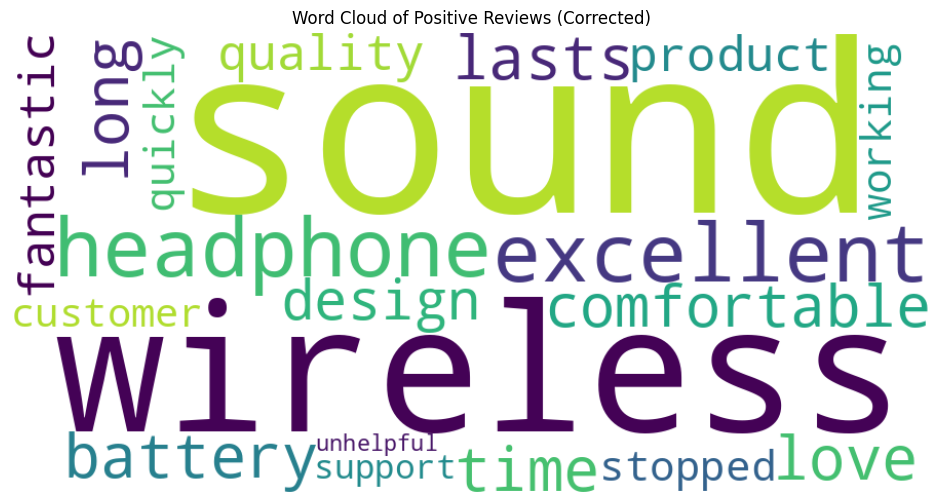

In [13]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Ensure the VADER lexicon is downloaded
nltk.download('vader_lexicon')

# Initialize the VADER sentiment analyzer
sia = SentimentIntensityAnalyzer()

# Five sample product reviews
reviews = [
    "This wireless headphone sounds excellent and the battery lasts a long time.",
    "I love the comfortable design and the sound quality is fantastic.",
    "The product stopped working quickly and customer support was unhelpful.",
    "Very disappointing purchase; the connection keeps dropping.",
    "The package arrived today. The box contains one headphone and a charging cable."
]

# Stopwords for the word cloud
stop_words = set(nltk.corpus.stopwords.words('english'))

# Calculate sentiment using VADER
positive_reviews = []

print("UPDATED SENTIMENT ANALYSIS RESULTS (VADER)")

for i, review in enumerate(reviews, start=1):
    scores = sia.polarity_scores(review)
    compound_score = scores['compound']

    # Classify based on compound score
    if compound_score >= 0.05:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif compound_score <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"\nReview {i}: {review}")
    print(f"Compound Score: {compound_score:.3f} | Sentiment: {sentiment}")

# Generate a word cloud from positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=900,
        height=450,
        background_color='white',
        stopwords=stop_words,
        collocations=False
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title("Word Cloud of Positive Reviews (Corrected)")
    plt.show()
else:
    print("\nNo positive reviews were found.")

In [12]:

import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences, to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training data: approximately 100 words
training_text = """
Artificial intelligence is changing how people solve problems.
Machine learning finds patterns in data and helps computers make predictions.
Good data and careful testing improve model reliability.
Language models learn patterns from sequences of words.
A model receives examples, adjusts its parameters, and predicts what may come next.
Training requires many examples, enough computing resources, and evaluation.
Simple models can demonstrate the idea, but small datasets produce repetitive text.
Responsible AI should be transparent, useful, and designed with human needs in mind.
"""

# 2. Tokenize the text and create a vocabulary
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1

print("Vocabulary size:", total_words)
print("Word index:", tokenizer.word_index)

# 3. Create input sequences
input_sequences = []

for sentence in training_text.lower().split("."):
    sentence = sentence.strip()

    if not sentence:
        continue

    token_list = tokenizer.texts_to_sequences([sentence])[0]

    for i in range(2, len(token_list) + 1):
        input_sequences.append(token_list[:i])

# 4. Pad sequences to make them the same length
max_sequence_len = max(len(seq) for seq in input_sequences)

padded_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

# X = input words; y = next word to predict
X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

# One-hot encode the target words
y = to_categorical(y, num_classes=total_words)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

# 5. Build the LSTM model
model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=32
    ),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)
model.build(input_shape=(None, X.shape[1]))

model.summary()

# 6. Train the model
model.fit(X, y, epochs=100, verbose=0)

print("Model training completed!")

# 7. Generate text from a seed phrase
def generate_text(seed_text, next_words=25):
    result = seed_text.lower()

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre',
            truncating='pre'
        )

        predicted_probs = model.predict(
            token_list,
            verbose=0
        )[0]

        predicted_id = int(np.argmax(predicted_probs))

        output_word = None

        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                output_word = word
                break

        if output_word is None:
            break

        result += " " + output_word

    return result

# 8. Generate 2–3 lines of new text
seed = "machine learning"
generated_text = generate_text(seed, next_words=25)

print("\nGenerated text:")
print(generated_text)


Vocabulary size: 73
Word index: {'and': 1, 'patterns': 2, 'in': 3, 'data': 4, 'model': 5, 'models': 6, 'examples': 7, 'artificial': 8, 'intelligence': 9, 'is': 10, 'changing': 11, 'how': 12, 'people': 13, 'solve': 14, 'problems': 15, 'machine': 16, 'learning': 17, 'finds': 18, 'helps': 19, 'computers': 20, 'make': 21, 'predictions': 22, 'good': 23, 'careful': 24, 'testing': 25, 'improve': 26, 'reliability': 27, 'language': 28, 'learn': 29, 'from': 30, 'sequences': 31, 'of': 32, 'words': 33, 'a': 34, 'receives': 35, 'adjusts': 36, 'its': 37, 'parameters': 38, 'predicts': 39, 'what': 40, 'may': 41, 'come': 42, 'next': 43, 'training': 44, 'requires': 45, 'many': 46, 'enough': 47, 'computing': 48, 'resources': 49, 'evaluation': 50, 'simple': 51, 'can': 52, 'demonstrate': 53, 'the': 54, 'idea': 55, 'but': 56, 'small': 57, 'datasets': 58, 'produce': 59, 'repetitive': 60, 'text': 61, 'responsible': 62, 'ai': 63, 'should': 64, 'be': 65, 'transparent': 66, 'useful': 67, 'designed': 68, 'with': 

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 12, 32)         │         2,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 73)             │         4,745 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,913 (124.66 KB)

 Trainable params: 31,913 (124.66 KB)

 Non-trainable params: 0 (0.00 B)

Model training completed!

Generated text:
machine learning data data and and helps computers computers predictions predictions predictions predictions predictions predictions mind mind mind human needs needs needs mind mind mind mind mind
